**title**


# Task 6: Final Capstone - NIFTY 50 Risk Radar
Problem: a retail investor or advisory team needs to know which Indian stocks are risky, when a stock is about to enter a high-volatility period, and how to build a lower-risk portfolio.
Data: daily prices of 25 NIFTY 50 stocks + NIFTY index + India VIX (Yahoo Finance, 2016 to Oct 2026)
Parts: (1) risk KPIs  (2) risk groups with KMeans  (3) high-volatility alert model  (4) portfolio back-test

**load data**


In [3]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

tickers = ["RELIANCE", "TCS", "HDFCBANK", "INFY", "ICICIBANK", "HINDUNILVR", "ITC", "SBIN", "BHARTIARTL",
           "KOTAKBANK", "LT", "AXISBANK", "ASIANPAINT", "MARUTI", "SUNPHARMA", "TITAN", "BAJFINANCE", "WIPRO",
           "NTPC", "ONGC", "ULTRACEMCO", "NESTLEIND", "POWERGRID", "TATASTEEL", "HCLTECH"]
symbols = [t + ".NS" for t in tickers] + ["^NSEI", "^INDIAVIX"]

raw = yf.download(symbols, start="2016-01-01", end="2026-11-01", auto_adjust=True, progress=False)
close = raw["Close"].copy()
volume = raw["Volume"].copy()

print("raw close shape:", close.shape)

raw close shape: (2675, 27)


**cleaning**

In [4]:
# fill small gaps (holidays differ between the index, VIX and stocks), then drop any day still incomplete
rows_before = len(close)
close = close.sort_index().ffill(limit=3).dropna(how="any")
volume = volume.reindex(close.index)

print("rows before:", rows_before, "| rows after:", len(close))
print("missing values left:", int(close.isnull().sum().sum()))
print("period:", close.index.min().date(), "to", close.index.max().date())

# split into stocks, index and VIX (remove the .NS from the names)
stock = close[[t + ".NS" for t in tickers]].copy()
stock.columns = tickers
vol_stock = volume[[t + ".NS" for t in tickers]].copy()
vol_stock.columns = tickers
nifty = close["^NSEI"]
vix = close["^INDIAVIX"]

ret = stock.pct_change().dropna()          # daily returns of each stock
nifty_ret = nifty.pct_change().dropna()

# save a clean copy for GitHub
close.to_csv("nifty_prices_clean.csv")
print("daily returns shape:", ret.shape)

rows before: 2675 | rows after: 2674
missing values left: 0
period: 2016-01-04 to 2026-10-30
daily returns shape: (2673, 25)


**risk and return KPIs**

In [5]:
# ----- risk and return KPIs for each stock -----
TRADING_DAYS = 252
RISK_FREE = 0.06      # assumption: 6% a year, close to Indian government bond yields

years = len(ret) / TRADING_DAYS
ann_ret = (1 + ret).prod() ** (1 / years) - 1          # compound annual growth rate
ann_vol = ret.std() * np.sqrt(TRADING_DAYS)            # yearly volatility
sharpe = (ann_ret - RISK_FREE) / ann_vol               # return earned per unit of risk

growth = (1 + ret).cumprod()
drawdown = growth / growth.cummax() - 1                # fall from the previous peak
max_dd = drawdown.min()

beta = ret.apply(lambda s: s.cov(nifty_ret) / nifty_ret.var())   # sensitivity to the market

stats = pd.DataFrame({"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": sharpe, "max_dd": max_dd, "beta": beta})
print("NIFTY 50 index: CAGR", round(((1 + nifty_ret).prod() ** (1 / years) - 1) * 100, 1), "%, volatility",
      round(nifty_ret.std() * np.sqrt(TRADING_DAYS) * 100, 1), "%")
print()
print((stats * [100, 100, 1, 100, 1]).round(2).sort_values("sharpe", ascending=False).to_string())

NIFTY 50 index: CAGR 10.8 %, volatility 16.1 %

            ann_ret  ann_vol  sharpe  max_dd  beta
TITAN         27.52    29.24    0.74  -41.73  0.93
BAJFINANCE    29.97    35.58    0.67  -62.44  1.39
BHARTIARTL    20.40    28.70    0.50  -46.78  0.82
TATASTEEL     23.08    35.06    0.49  -64.50  1.30
ICICIBANK     19.30    29.68    0.45  -48.31  1.29
POWERGRID     17.11    25.06    0.44  -29.56  0.64
LT            17.35    26.63    0.43  -54.44  1.12
NESTLEIND     15.69    22.29    0.43  -24.22  0.52
RELIANCE      17.29    26.76    0.42  -45.09  1.08
HCLTECH       15.61    26.51    0.36  -44.76  0.74
ULTRACEMCO    14.67    26.16    0.33  -37.50  1.02
SBIN          16.20    32.33    0.32  -59.49  1.29
NTPC          13.72    25.70    0.30  -46.83  0.76
KOTAKBANK     11.91    25.74    0.23  -36.50  1.00
HDFCBANK      10.42    22.61    0.20  -41.05  1.02
ASIANPAINT    10.49    24.24    0.19  -39.04  0.74
INFY          10.70    26.93    0.17  -48.17  0.82
TCS            9.98    24.27    0.

**charts 1 and 2**

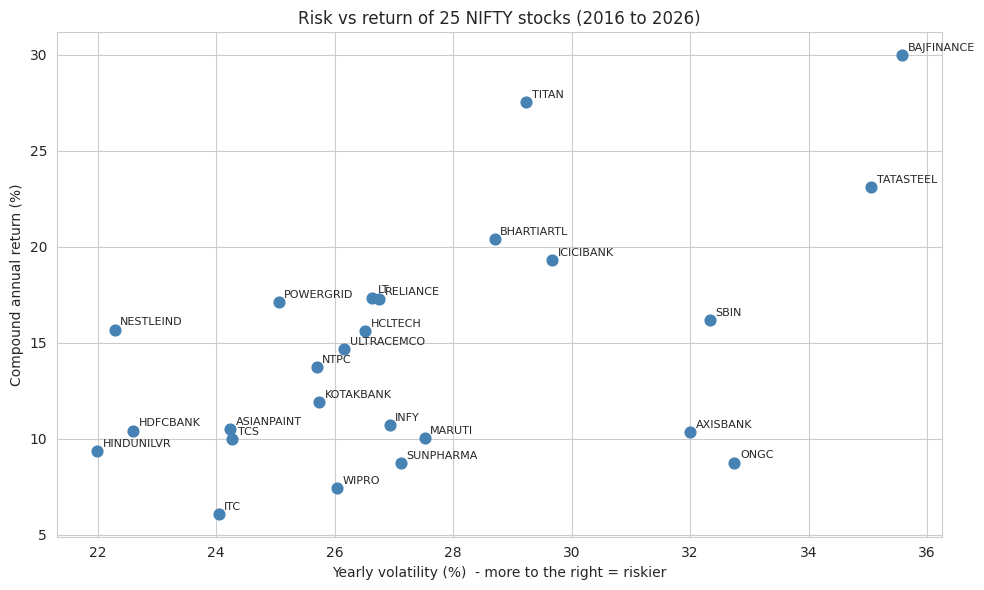

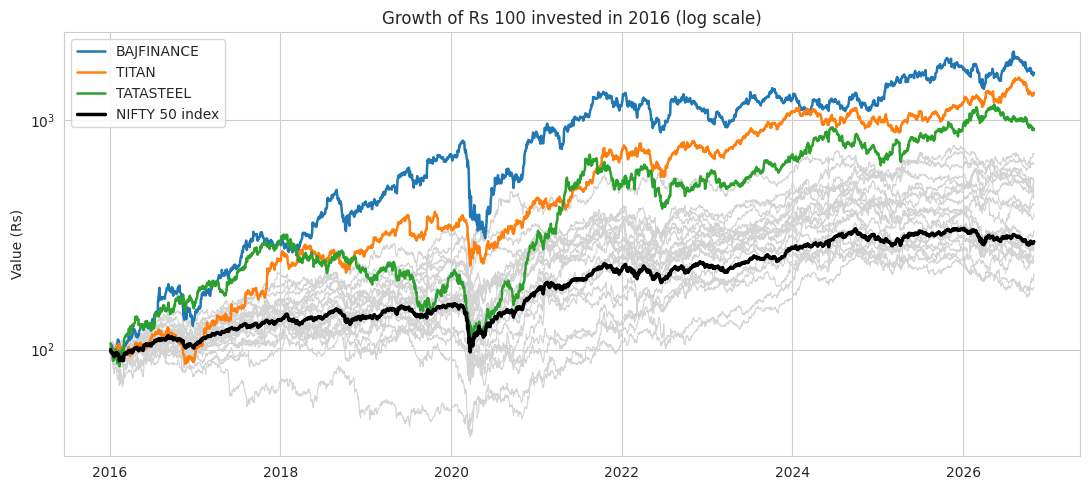

Final value of Rs 100:  NIFTY 296 | best 3: {'BAJFINANCE': 1613.0, 'TITAN': 1318.0, 'TATASTEEL': 905.0} | worst: ITC 187


In [6]:
# Chart 1: risk vs return
plt.figure(figsize=(10, 6))
plt.scatter(stats["ann_vol"] * 100, stats["ann_ret"] * 100, s=60, color="steelblue")
for name, row in stats.iterrows():
    plt.annotate(name, (row["ann_vol"] * 100, row["ann_ret"] * 100), fontsize=8, xytext=(4, 3), textcoords="offset points")
plt.xlabel("Yearly volatility (%)  - more to the right = riskier")
plt.ylabel("Compound annual return (%)")
plt.title("Risk vs return of 25 NIFTY stocks (2016 to 2026)")
plt.tight_layout(); plt.show()

# Chart 2: growth of Rs 100
idx100 = growth * 100
nifty_growth = (1 + nifty_ret).cumprod() * 100
plt.figure(figsize=(11, 5))
for s in idx100.columns:
    plt.plot(idx100.index, idx100[s], color="lightgray", linewidth=0.8)
best3 = idx100.iloc[-1].sort_values(ascending=False).head(3).index
for s in best3:
    plt.plot(idx100.index, idx100[s], linewidth=1.8, label=s)
plt.plot(nifty_growth.index, nifty_growth, color="black", linewidth=2.5, label="NIFTY 50 index")
plt.yscale("log")
plt.title("Growth of Rs 100 invested in 2016 (log scale)")
plt.ylabel("Value (Rs)"); plt.legend()
plt.tight_layout(); plt.show()
print("Final value of Rs 100:  NIFTY", round(nifty_growth.iloc[-1]), "| best 3:", idx100.iloc[-1][best3].round().to_dict(),
      "| worst:", idx100.iloc[-1].idxmin(), round(idx100.iloc[-1].min()))

**charts 3 and 4**

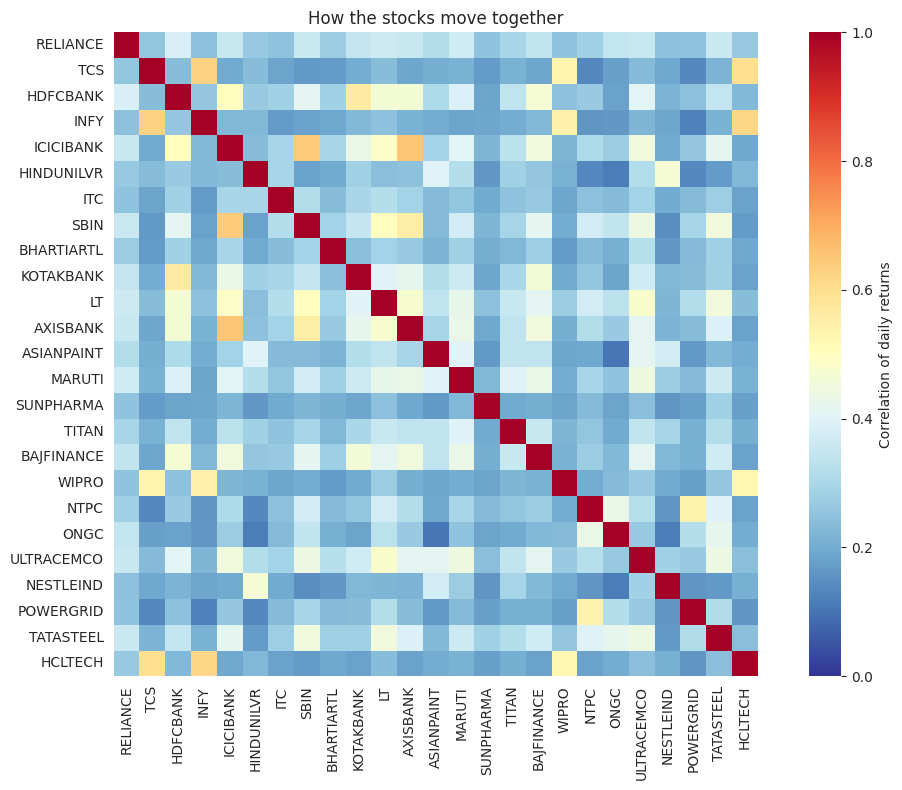

Average pairwise correlation: 0.28
Most similar pairs:
 ICICIBANK  AXISBANK    0.65
           SBIN        0.64
TCS        INFY        0.63
dtype: float64
Least similar pairs:
 HINDUNILVR  ONGC         0.12
ONGC        NESTLEIND    0.12
ASIANPAINT  ONGC         0.10
dtype: float64


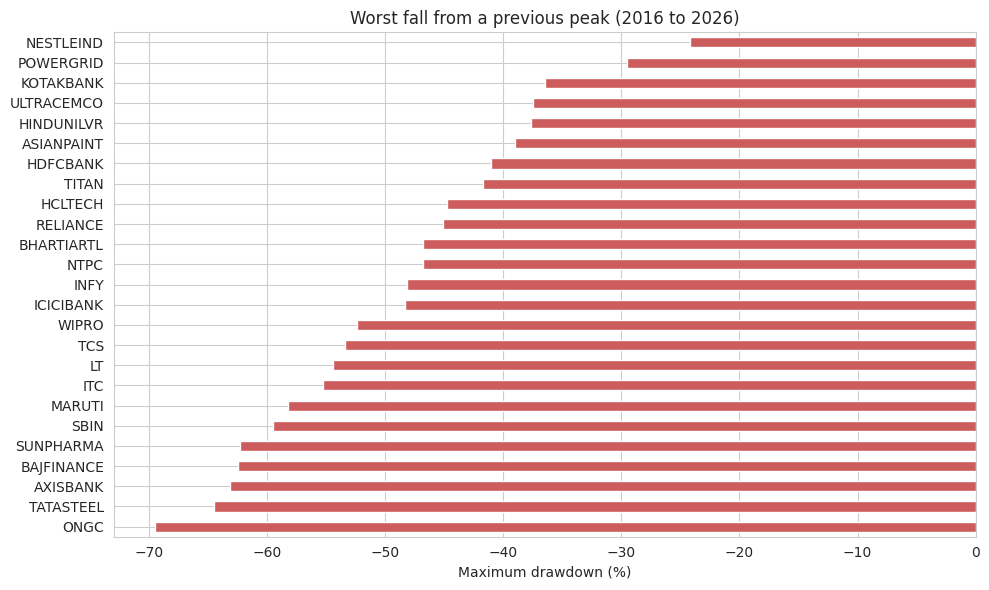

Date of the worst market-wide fall (average of all stocks): 2020-03-23 -42.8 %


In [7]:
# Chart 3: correlation between stocks
corr = ret.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="RdYlBu_r", vmin=0, vmax=1, square=True, cbar_kws={"label": "Correlation of daily returns"})
plt.title("How the stocks move together")
plt.tight_layout(); plt.show()
avg_corr = (corr.values.sum() - len(corr)) / (len(corr) * (len(corr) - 1))
print("Average pairwise correlation:", round(avg_corr, 2))
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna().sort_values(ascending=False)
print("Most similar pairs:\n", pairs.head(3).round(2))
print("Least similar pairs:\n", pairs.tail(3).round(2))

# Chart 4: worst fall from peak
plt.figure(figsize=(10, 6))
(stats["max_dd"].sort_values() * 100).plot(kind="barh", color="indianred")
plt.xlabel("Maximum drawdown (%)"); plt.title("Worst fall from a previous peak (2016 to 2026)")
plt.tight_layout(); plt.show()
print("Date of the worst market-wide fall (average of all stocks):",
      drawdown.mean(axis=1).idxmin().date(), round(drawdown.mean(axis=1).min() * 100, 1), "%")

**risk groups (KMeans)**

k  silhouette
2 0.37
3 0.266
4 0.273
5 0.295
6 0.27

chosen k = 5
            stocks  ann_ret  ann_vol  max_dd  beta  sharpe
risk_group                                                
Group 1          9    13.22    24.48  -37.46  0.78    0.29
Group 2          6     8.82    25.99  -54.97  0.78    0.11
Group 3          5    20.37    28.20  -47.27  1.05    0.51
Group 4          3    11.77    32.36  -64.04  1.17    0.18
Group 5          2    26.53    35.32  -63.47  1.34    0.58
Group 1 : HDFCBANK, HINDUNILVR, KOTAKBANK, ASIANPAINT, NTPC, ULTRACEMCO, NESTLEIND, POWERGRID, HCLTECH
Group 2 : TCS, INFY, ITC, MARUTI, SUNPHARMA, WIPRO
Group 3 : RELIANCE, ICICIBANK, BHARTIARTL, LT, TITAN
Group 4 : SBIN, AXISBANK, ONGC
Group 5 : BAJFINANCE, TATASTEEL


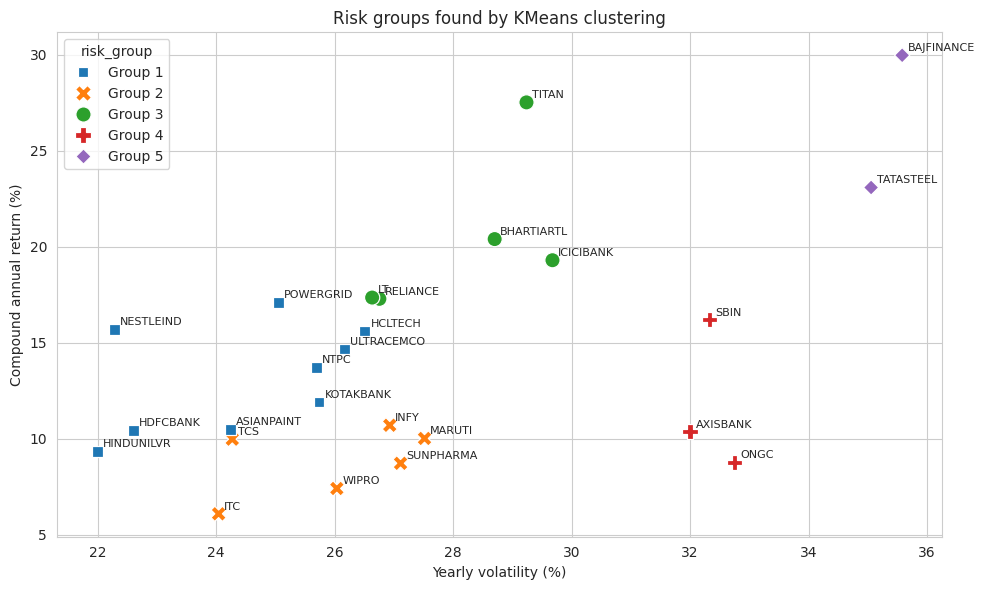

In [8]:
# ----- group the stocks into risk profiles with KMeans -----
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

feat = stats[["ann_ret", "ann_vol", "max_dd", "beta"]]
X_scaled = StandardScaler().fit_transform(feat)

print("k  silhouette")
scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
    print(k, round(scores[k], 3))

# choose the best k between 3 and 5 (at least 3 groups so the result is useful)
best_k = max([3, 4, 5], key=lambda k: scores[k])
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
stats["cluster"] = km.fit_predict(X_scaled)

# name the groups by their average volatility (1 = calmest)
rank = stats.groupby("cluster")["ann_vol"].mean().rank().astype(int)
stats["risk_group"] = "Group " + stats["cluster"].map(rank).astype(str)
print("\nchosen k =", best_k)
summary = stats.groupby("risk_group").agg(stocks=("ann_ret", "size"), ann_ret=("ann_ret", "mean"), ann_vol=("ann_vol", "mean"),
                                           max_dd=("max_dd", "mean"), beta=("beta", "mean"), sharpe=("sharpe", "mean"))
print((summary * [1, 100, 100, 100, 1, 1]).round(2).to_string())
for g, members in stats.groupby("risk_group"):
    print(g, ":", ", ".join(members.index))

plt.figure(figsize=(10, 6))
sns.scatterplot(data=stats, x=stats["ann_vol"] * 100, y=stats["ann_ret"] * 100, hue="risk_group", style="risk_group", s=120,
                hue_order=sorted(stats["risk_group"].unique()))
for name, row in stats.iterrows():
    plt.annotate(name, (row["ann_vol"] * 100, row["ann_ret"] * 100), fontsize=8, xytext=(4, 3), textcoords="offset points")
plt.xlabel("Yearly volatility (%)"); plt.ylabel("Compound annual return (%)")
plt.title("Risk groups found by KMeans clustering")
plt.tight_layout(); plt.show()

**build the alert-model dataset**

In [9]:
# ----- build the dataset for the high-volatility alert model -----
# Question: will the next 5 trading days be unusually volatile for this stock?
# Unusually volatile = the next 5-day volatility is above the stock's own 75th percentile of the past year.
nifty_ret_full = nifty.pct_change()
pieces = []
for s in stock.columns:
    p = stock[s]
    r = p.pct_change()
    d = pd.DataFrame(index=stock.index)
    d["stock"] = s
    # features: only information known on day t
    d["ret_1d"] = r
    d["ret_5d"] = p.pct_change(5)
    d["ret_20d"] = p.pct_change(20)
    d["vol_5d"] = r.rolling(5).std()
    d["vol_20d"] = r.rolling(20).std()
    d["vol_60d"] = r.rolling(60).std()
    d["vol_ratio"] = d["vol_5d"] / d["vol_20d"]
    d["from_high_60d"] = p / p.rolling(60).max() - 1
    d["volume_ratio"] = vol_stock[s] / vol_stock[s].rolling(20).mean()
    d["vix"] = vix
    d["vix_chg_5d"] = vix.pct_change(5)
    d["nifty_ret_5d"] = nifty.pct_change(5)
    d["nifty_vol_20d"] = nifty_ret_full.rolling(20).std()
    # target: volatility of the NEXT 5 days compared with this stock's own past year
    threshold = d["vol_5d"].rolling(250).quantile(0.75)
    future_vol = r.rolling(5).std().shift(-5)
    d["vol_vs_threshold"] = d["vol_5d"] / threshold      # today's volatility vs the threshold (used for the baseline)
    d["target"] = np.where(future_vol.isnull() | threshold.isnull(), np.nan, (future_vol > threshold).astype(float))
    pieces.append(d)

panel = pd.concat(pieces)
panel = panel.replace([np.inf, -np.inf], np.nan).dropna()
panel["target"] = panel["target"].astype(int)

features = ["ret_1d", "ret_5d", "ret_20d", "vol_5d", "vol_20d", "vol_60d", "vol_ratio", "from_high_60d",
            "volume_ratio", "vix", "vix_chg_5d", "nifty_ret_5d", "nifty_vol_20d"]

print("rows:", len(panel), "| period:", panel.index.min().date(), "to", panel.index.max().date())
print("share of high-volatility days:", round(panel["target"].mean() * 100, 1), "%")
print(panel[features].describe().round(3).T[["mean", "min", "max"]].to_string())

rows: 60375 | period: 2017-01-13 to 2026-10-23
share of high-volatility days: 25.5 %
                 mean    min     max
ret_1d          0.001 -0.279   0.277
ret_5d          0.003 -0.393   0.393
ret_20d         0.014 -0.585   0.654
vol_5d          0.015  0.000   0.147
vol_20d         0.016  0.003   0.098
vol_60d         0.016  0.006   0.069
vol_ratio       0.937  0.032   2.142
from_high_60d  -0.066 -0.620   0.000
volume_ratio    1.013  0.000  15.269
vix            16.426  9.150  83.610
vix_chg_5d      0.006 -0.448   1.296
nifty_ret_5d    0.002 -0.190   0.105
nifty_vol_20d   0.009  0.003   0.056


**train and compare models**

In [10]:
# ----- train and test: split by TIME (never random, so the model cannot peek into the future) -----
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# 7-day gap between train and test, because each target looks 5 days ahead
train = panel[panel.index <= "2022-12-20"]
test = panel[panel.index >= "2023-01-01"]
X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]
print("train rows:", len(train), "(", train.index.min().date(), "to", train.index.max().date(), ")")
print("test rows :", len(test), "(", test.index.min().date(), "to", test.index.max().date(), ")")
print("high-vol share  train:", round(y_train.mean() * 100, 1), "%  test:", round(y_test.mean() * 100, 1), "%")

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50, class_weight="balanced",
                                            n_jobs=-1, random_state=42),
}

results = []
probs = {}

# baseline 1: always predict "calm"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p0 = dummy.predict(X_test)
results.append(["Baseline: always calm", accuracy_score(y_test, p0), precision_score(y_test, p0, zero_division=0),
                recall_score(y_test, p0), f1_score(y_test, p0, zero_division=0), 0.5])

# baseline 2: "persistence" - if volatility is high today, predict it stays high
p1 = (test["vol_vs_threshold"] > 1).astype(int)
results.append(["Baseline: persistence rule", accuracy_score(y_test, p1), precision_score(y_test, p1, zero_division=0),
                recall_score(y_test, p1), f1_score(y_test, p1, zero_division=0), roc_auc_score(y_test, test["vol_vs_threshold"])])

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    probs[name] = m.predict_proba(X_test)[:, 1]
    results.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
                    f1_score(y_test, pred), roc_auc_score(y_test, probs[name])])

res = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).set_index("Model")
print()
print(res.round(3).to_string())

train rows: 36675 ( 2017-01-13 to 2022-12-20 )
test rows : 23500 ( 2023-01-02 to 2026-10-23 )
high-vol share  train: 25.1 %  test: 26.3 %

                            Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                                  
Baseline: always calm          0.737      0.000   0.000  0.000    0.500
Baseline: persistence rule     0.652      0.335   0.331  0.333    0.583
Logistic Regression            0.649      0.351   0.396  0.372    0.592
Random Forest                  0.676      0.354   0.286  0.317    0.584


**evaluation charts**

best model: Logistic Regression


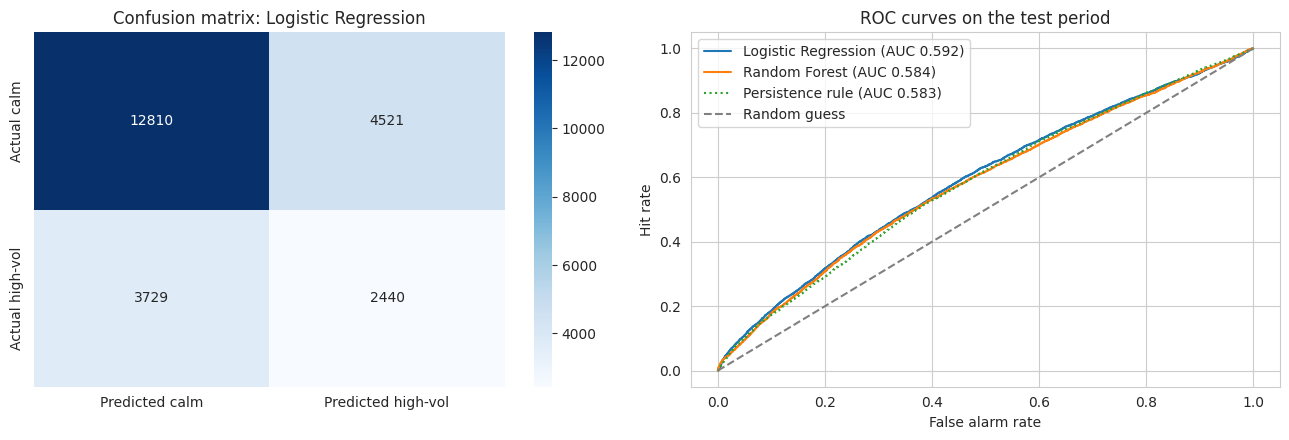

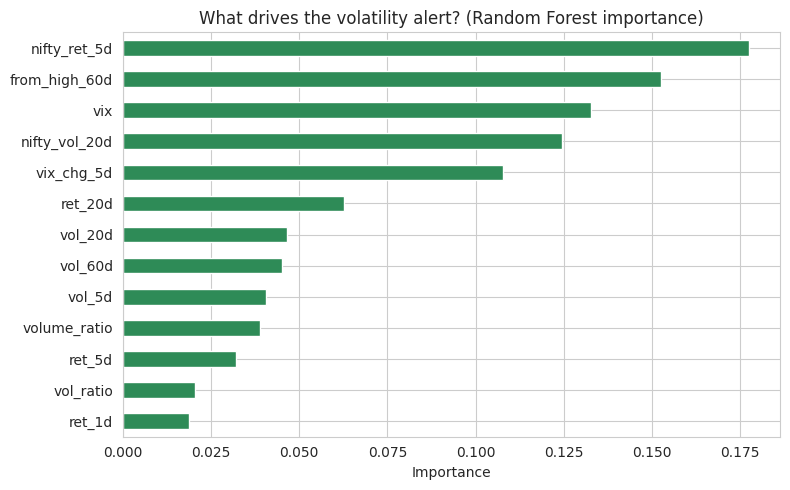

top 5 features: {'nifty_ret_5d': 0.177, 'from_high_60d': 0.152, 'vix': 0.133, 'nifty_vol_20d': 0.124, 'vix_chg_5d': 0.108}


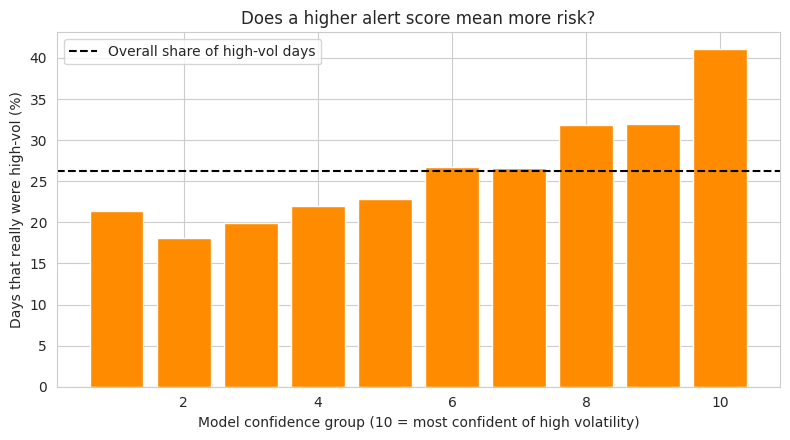

Top decile:  41.1 % were high-vol  | bottom decile: 21.4 % | overall: 26.3 %


In [11]:
# ----- evaluation charts for the best model -----
best_name = res.drop(index=["Baseline: always calm", "Baseline: persistence rule"])["ROC-AUC"].idxmax()
best = models[best_name]
pred = best.predict(X_test)
print("best model:", best_name)

cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Predicted calm", "Predicted high-vol"], yticklabels=["Actual calm", "Actual high-vol"])
ax[0].set_title("Confusion matrix: " + best_name)

for name in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax[1].plot(fpr, tpr, label=name + " (AUC " + str(round(roc_auc_score(y_test, probs[name]), 3)) + ")")
fpr, tpr, _ = roc_curve(y_test, test["vol_vs_threshold"])
ax[1].plot(fpr, tpr, label="Persistence rule (AUC " + str(round(roc_auc_score(y_test, test["vol_vs_threshold"]), 3)) + ")", linestyle=":")
ax[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
ax[1].set_xlabel("False alarm rate"); ax[1].set_ylabel("Hit rate"); ax[1].set_title("ROC curves on the test period"); ax[1].legend()
plt.tight_layout(); plt.show()

# which features matter (only for Random Forest)
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="seagreen")
plt.title("What drives the volatility alert? (Random Forest importance)")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()
print("top 5 features:", imp.sort_values(ascending=False).head(5).round(3).to_dict())

# business view: when the model is most sure, how often is it right?
tmp = pd.DataFrame({"prob": probs[best_name], "actual": y_test.values})
tmp["decile"] = pd.qcut(tmp["prob"].rank(method="first"), 10, labels=False) + 1
dec = tmp.groupby("decile")["actual"].mean() * 100
plt.figure(figsize=(8, 4.5))
plt.bar(dec.index, dec.values, color="darkorange")
plt.axhline(y_test.mean() * 100, color="black", linestyle="--", label="Overall share of high-vol days")
plt.xlabel("Model confidence group (10 = most confident of high volatility)")
plt.ylabel("Days that really were high-vol (%)"); plt.title("Does a higher alert score mean more risk?")
plt.legend(); plt.tight_layout(); plt.show()
print("Top decile: ", round(dec.iloc[-1], 1), "% were high-vol  | bottom decile:", round(dec.iloc[0], 1), "% | overall:", round(y_test.mean() * 100, 1), "%")

**portfolio back-test**

Back-test period: 2017-02-01 to 2026-10-30
                  CAGR %  Volatility %  Sharpe  Max drawdown %
Equal weight       17.34         15.44    0.73          -34.37
Minimum variance   15.40         13.47    0.70          -26.80
NIFTY 50 index     10.92         16.26    0.30          -38.44

COVID crash (19 Feb to 23 Mar 2020) return: {'Equal weight': -33.1, 'Minimum variance': -24.7, 'NIFTY 50 index': -36.5}


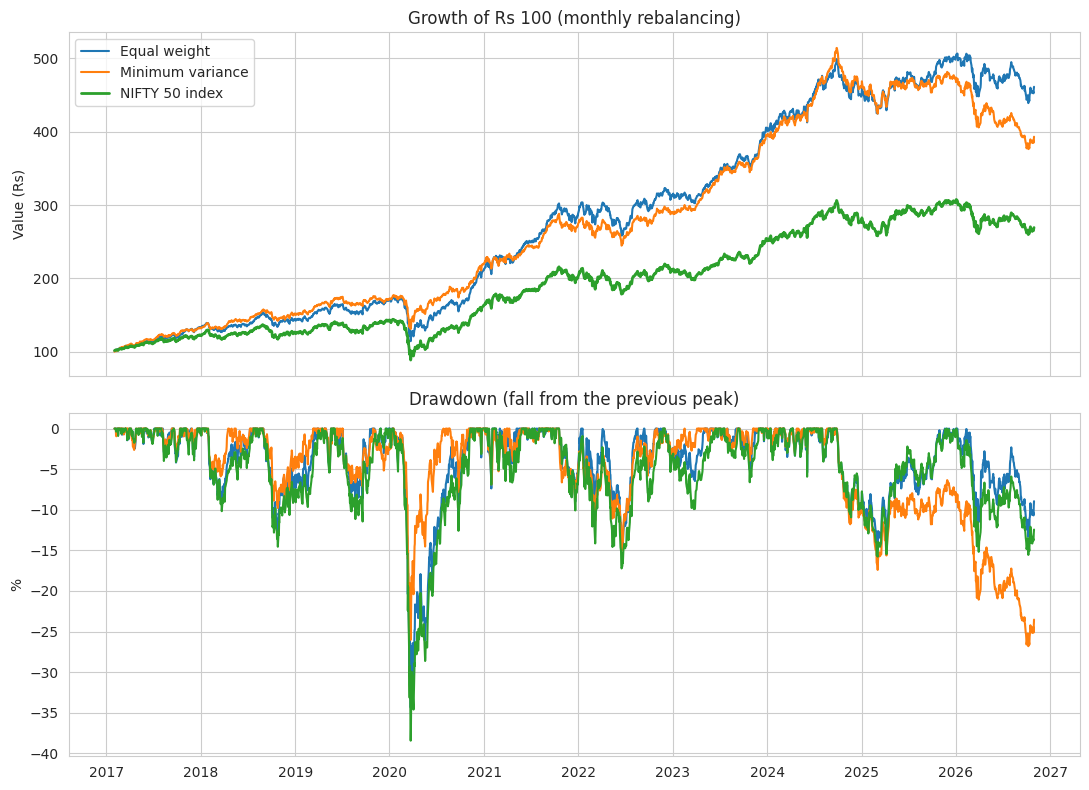


Average minimum-variance weights (top 6, %):
{'NESTLEIND': 9.2, 'HINDUNILVR': 9.0, 'SUNPHARMA': 8.9, 'HDFCBANK': 8.4, 'POWERGRID': 8.1, 'TCS': 7.9}


In [12]:
# ----- portfolio back-test: equal weight vs minimum-variance vs the NIFTY index -----
from scipy.optimize import minimize

def min_variance_weights(cov, max_weight=0.15):
    n = cov.shape[0]
    start = np.ones(n) / n
    res = minimize(lambda w: w @ cov @ w, start, method="SLSQP", bounds=[(0, max_weight)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return res.x if res.success else start

# rebalance on the last trading day of every month, using only the past 252 days of data
last_days = ret.index.to_series().groupby(ret.index.to_period("M")).last().tolist()
rebalance_days = [d for d in last_days if len(ret.loc[:d]) >= 252]

eq_parts, mv_parts, weights_log = [], [], []
n = ret.shape[1]
for i, day in enumerate(rebalance_days[:-1]):
    nxt = rebalance_days[i + 1]
    window = ret.loc[:day].tail(252)
    w_mv = min_variance_weights(window.cov().values * TRADING_DAYS)
    w_eq = np.ones(n) / n
    weights_log.append(pd.Series(w_mv, index=ret.columns, name=day))
    period = ret.loc[ret.index > day].loc[:nxt]            # the next month of returns
    for w, store in [(w_eq, eq_parts), (w_mv, mv_parts)]:
        value = (1 + period).cumprod().values @ w          # buy and hold inside the month
        previous = np.r_[1.0, value[:-1]]
        store.append(pd.Series(value / previous - 1, index=period.index))

eq_ret = pd.concat(eq_parts)
mv_ret = pd.concat(mv_parts)
bench_ret = nifty_ret.loc[eq_ret.index]
curves = pd.DataFrame({"Equal weight": eq_ret, "Minimum variance": mv_ret, "NIFTY 50 index": bench_ret})

def perf(r):
    yrs = len(r) / TRADING_DAYS
    cagr = (1 + r).prod() ** (1 / yrs) - 1
    vol = r.std() * np.sqrt(TRADING_DAYS)
    g = (1 + r).cumprod()
    return {"CAGR %": cagr * 100, "Volatility %": vol * 100, "Sharpe": (cagr - RISK_FREE) / vol,
            "Max drawdown %": (g / g.cummax() - 1).min() * 100}

table = pd.DataFrame({c: perf(curves[c]) for c in curves}).T
print("Back-test period:", curves.index.min().date(), "to", curves.index.max().date())
print(table.round(2).to_string())

covid = curves.loc["2020-02-19":"2020-03-23"]
print("\nCOVID crash (19 Feb to 23 Mar 2020) return:", ((1 + covid).prod() - 1).mul(100).round(1).to_dict())

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for c in curves:
    g = (1 + curves[c]).cumprod() * 100
    ax[0].plot(g.index, g, label=c, linewidth=2 if c == "NIFTY 50 index" else 1.5)
    ax[1].plot(g.index, (g / g.cummax() - 1) * 100, label=c)
ax[0].set_title("Growth of Rs 100 (monthly rebalancing)"); ax[0].legend(); ax[0].set_ylabel("Value (Rs)")
ax[1].set_title("Drawdown (fall from the previous peak)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

avg_w = pd.concat(weights_log, axis=1).mean(axis=1).sort_values(ascending=False)
print("\nAverage minimum-variance weights (top 6, %):")
print((avg_w.head(6) * 100).round(1).to_dict())

**numbers for the report**

In [13]:
# ----- numbers for the report -----
print("DATA:", len(close), "days,", close.index.min().date(), "to", close.index.max().date(), "|", len(tickers), "stocks")
print("Highest Sharpe:", stats["sharpe"].idxmax(), round(stats["sharpe"].max(), 2), "| lowest:", stats["sharpe"].idxmin(), round(stats["sharpe"].min(), 2))
print("Highest volatility:", stats["ann_vol"].idxmax(), round(stats["ann_vol"].max() * 100, 1), "% | lowest:", stats["ann_vol"].idxmin(), round(stats["ann_vol"].min() * 100, 1), "%")
print("Highest beta:", stats["beta"].idxmax(), round(stats["beta"].max(), 2), "| lowest:", stats["beta"].idxmin(), round(stats["beta"].min(), 2))
print("Deepest drawdown:", stats["max_dd"].idxmin(), round(stats["max_dd"].min() * 100, 1), "%")
print("Risk groups:", stats["risk_group"].value_counts().sort_index().to_dict())
print("Best model:", best_name)
print(res.round(3).to_string())
print("Average VIX on high-vol days vs calm days:", panel.groupby("target")["vix"].mean().round(1).to_dict())

DATA: 2674 days, 2016-01-04 to 2026-10-30 | 25 stocks
Highest Sharpe: TITAN 0.74 | lowest: ITC 0.0
Highest volatility: BAJFINANCE 35.6 % | lowest: HINDUNILVR 22.0 %
Highest beta: BAJFINANCE 1.39 | lowest: NESTLEIND 0.52
Deepest drawdown: ONGC -69.5 %
Risk groups: {'Group 1': 9, 'Group 2': 6, 'Group 3': 5, 'Group 4': 3, 'Group 5': 2}
Best model: Logistic Regression
                            Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                                  
Baseline: always calm          0.737      0.000   0.000  0.000    0.500
Baseline: persistence rule     0.652      0.335   0.331  0.333    0.583
Logistic Regression            0.649      0.351   0.396  0.372    0.592
Random Forest                  0.676      0.354   0.286  0.317    0.584
Average VIX on high-vol days vs calm days: {0: 15.7, 1: 18.5}
